# LAB 02 — Nastanjiva zona i greske
**Astrobiologija**

**Istraživačko pitanje:** Koliko su procene nastanjive zone i rang kandidata stabilni kada uključimo merenja i klimatske pretpostavke?


## 1. Kratak teorijski uvod

### Luminoznost i primljeni fluks
Stefan–Bolcmanov zakon za približno crno-telo zvezdu:

$$L_\star=4\pi R_\star^2\sigma T_{\rm eff}^4,$$

odnosno u Sunčevim jedinicama:

$$\frac{L_\star}{L_\odot}=\left(\frac{R_\star}{R_\odot}\right)^2\left(\frac{T_{\rm eff}}{5772\,{\rm K}}\right)^4.$$

Fluks na približno kružnoj orbiti poluprečnika $a$:

$$F=\frac{L_\star}{4\pi a^2},\qquad S=\frac{F}{F_\oplus}=\frac{L_\star/L_\odot}{(a/{\rm AU})^2}.$$

### Ravnotežna temperatura
Ako planeta ima Bondov albedo $A$ i ravnomerno emituje kao crno telo:

$$\pi R_p^2 F(1-A)=4\pi R_p^2\sigma T_{\rm eq}^4,$$

$$T_{\rm eq}=\left[\frac{F(1-A)}{4\sigma}\right]^{1/4}.$$

Za Zemlju pri $A\approx0.3$ očekuje se **$T_{\rm eq}\approx255$ K**. Prosečna površinska temperatura od približno 288 K nije isto što i ravnotežna temperatura: atmosfera stvara efekat staklene bašte.

## 2. Granice nastanjive zone — Kopparapu et al. (2014)

Klasična HZ je oblast u kojoj bi stenovita planeta sa odgovarajućom atmosferom mogla imati **tečnu površinsku vodu**. Za svaku izabranu granicu računamo kritični fluks:

$$S_{\rm eff}=S_0+\alpha T'+\beta T'^2+\gamma T'^3+\delta T'^4,\qquad T'=T_{\rm eff}-5780\,{\rm K},$$

$$d_{\rm HZ}=\sqrt{\frac{L_\star/L_\odot}{S_{\rm eff}}}\,{\rm AU}.$$

**Domen modela:** $2600\leq T_{\rm eff}\leq7200$ K; ne ekstrapolirati van njega. Koristimo granice za **planetu mase Zemlje**.

- **Konzervativna HZ:** unutrašnja *Runaway Greenhouse* (RG), spoljašnja *Maximum Greenhouse* (MG).
- **Optimistična HZ:** unutrašnja *Recent Venus* (RV), spoljašnja *Early Mars* (EM).

| Granica | $S_0$ | $\alpha$ | $\beta$ | $\gamma$ | $\delta$ |
|---|---:|---:|---:|---:|---:|
| RV | 1.776 | 2.136e−4 | 2.533e−8 | −1.332e−11 | −3.097e−15 |
| RG | 1.107 | 1.332e−4 | 1.580e−8 | −8.308e−12 | −1.931e−15 |
| MG | 0.356 | 6.171e−5 | 1.698e−9 | −3.198e−12 | −5.575e−16 |
| EM | 0.320 | 5.547e−5 | 1.526e−9 | −2.874e−12 | −5.011e−16 |

Za Sunce i RG–MG očekuje se približno **0.95–1.68 AU**. $S$ je stvarni primljeni relativni fluks, a $S_{\rm eff}$ prag određene klimatske granice.

**Izvor:** Kopparapu et al. (2014), *Habitable Zones Around Main-sequence Stars: Dependence on Planetary Mass*, ApJL 787, L29, https://doi.org/10.1088/2041-8205/787/2/L29.

## 3. Greske i Monte Karlo

Merenja $R_\star$, $T_{\rm eff}$ i $a$ imaju greske. Za male greške:

$$\left(\frac{\sigma_L}{L}\right)^2\simeq\left(2\frac{\sigma_R}{R}\right)^2+\left(4\frac{\sigma_T}{T}\right)^2,$$

$$\left(\frac{\sigma_S}{S}\right)^2\simeq\left(\frac{\sigma_L}{L}\right)^2+\left(2\frac{\sigma_a}{a}\right)^2.$$

Monte Karlo: uzorkovati fizički dozvoljene vrednosti, za svaki uzorak izračunati $L,S,T_{\rm eq}$ i HZ, pa izbrojati realizacije unutar zone:

$$\widehat P({\rm HZ}\mid\text{model, pretpostavke})=\frac{N_{\rm unutar}}{N}.$$

Ovo **nije** $P(\text{život})$. Uzećemo $N=50\,000$ i fiksni `seed=42`. Za parametre koji moraju biti pozitivni koristiti, na primer, normalnu raspodelu odsečenu na fizičkom domenu. Greske koje nedostaju **nisu nula**: napraviti više jasno označenih scenarija.

NASA Exoplanet Archive u tabelama PS/PSCompPars koristi `st_rad`, `st_teff`, `pl_orbsmax`, sa kolonama `err1` (gornja) i `err2` (donja greška). Kod stvarnih podataka proveriti reference, asimetrije i korelacije; ovde su podaci sintetički i greške simetrične.

**Klimatske pretpostavke:** promena albeda $A$ menja $T_{\rm eq}$; promena pretpostavljenog dodatnog atmosferskog zagrevanja menja ilustrativnu procenu površinske temperature. To **ne menja automatski** Kopparapu granice HZ.

## 4. Pokazni kod — biblioteke, konstante i demonstracija uzorkovanja

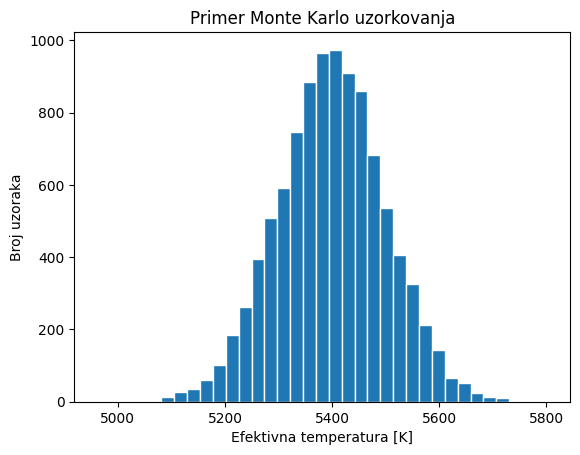

Sunčev fluks na 1 AU: 1361.2 W/m²


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
sigma_sb = 5.670374419e-8  # W m^-2 K^-4
L_sun = 3.828e26           # W
T_sun = 5772.0             # K
AU = 1.495978707e11        # m
F_earth = L_sun / (4 * np.pi * AU**2)

# Pokazni primer: raspodela izmerene temperature
T_demo = rng.normal(5400, 100, size=10000)
plt.hist(T_demo, bins=35, edgecolor='white')
plt.xlabel('Efektivna temperatura [K]')
plt.ylabel('Broj uzoraka')
plt.title('Primer Monte Karlo uzorkovanja')
plt.show()
print(f'Sunčev fluks na 1 AU: {F_earth:.1f} W/m²')

## 5. Ulazni podaci i koeficijenti 

In [2]:
# Kolone R, T i a izražene su u R_sun, K i AU.
# err kolone predstavljaju 1-sigma neizvesnosti (sintetički podaci).
candidates = pd.DataFrame([
    dict(name='Kandidat A', R=0.90, R_err=0.04, T=5400, T_err=100, a=0.90, a_err=0.03),
    dict(name='Kandidat B', R=0.75, R_err=0.05, T=4700, T_err=120, a=0.55, a_err=0.04),
    dict(name='Kandidat C', R=1.05, R_err=0.06, T=5900, T_err=150, a=1.55, a_err=np.nan),
])

# Redosled koeficijenata: S0, alpha, beta, gamma, delta
hz_coeff = {
    'RV': (1.776, 2.136e-4, 2.533e-8, -1.332e-11, -3.097e-15),
    'RG': (1.107, 1.332e-4, 1.580e-8, -8.308e-12, -1.931e-15),
    'MG': (0.356, 6.171e-5, 1.698e-9, -3.198e-12, -5.575e-16),
    'EM': (0.320, 5.547e-5, 1.526e-9, -2.874e-12, -5.011e-16),
}
display(candidates)

,name,R,R_err,T,T_err,a,a_err
0,Kandidat A,0.90,0.04,5400,100,0.90,0.03
1,Kandidat B,0.75,0.05,4700,120,0.55,0.04
2,Kandidat C,1.05,0.06,5900,150,1.55,NaN


# 6. Samostalni zadaci za studente

**Zadatak 1 — Osnovna fizika.** Napisati funkcije `stellar_luminosity(R,T)`, `incident_flux(L,a)` i `equilibrium_temperature(S,A)`. Za zvezdu $R=0.90R_\odot$, $T=5400$ K i planetu na $a=0.90$ AU izračunati $L,S,T_{\rm eq}$ za $A=0.1,0.3,0.6$. **Kontrola:** za Zemlju, $S=1$, $A=0.3$, približno 255 K. Zašto ne 288 K?



In [10]:
# Ulazi: R u R_sun, T u K, a u AU; izlazi L/L_sun i S/S_earth.
def stellar_luminosity(R, T):
    if R <= 0 or T <= 0:
        raise ValueError('R i T moraju biti pozitivni.')
    return R**2 * (T / T_sun)**4


def incident_flux(L, a):
    if L < 0 or a <= 0:
        raise ValueError('L ne može biti negativan, a a mora biti pozitivno.')
    return L / a**2


def equilibrium_temperature(S, A):
    if S < 0 or not 0 <= A <= 1:
        raise ValueError('S ne može biti negativan, a albedo A mora biti u [0, 1].')
    return (S * F_earth * (1 - A) / (4 * sigma_sb))**0.25


R, T, a = 0.90, 5400, 0.90
L = stellar_luminosity(R, T)
S = incident_flux(L, a)
rezultati_zadatka_1 = pd.DataFrame([
    {'A': A, 'L/L_sun': L, 'S/S_earth': S, 'T_eq [K]': equilibrium_temperature(S, A)}
    for A in (0.1, 0.3, 0.6)
])
display(rezultati_zadatka_1.round({'L/L_sun': 4, 'S/S_earth': 4, 'T_eq [K]': 1}))

# Kontrola: Zemlja, S=1 i A=0.3.
print(f'Zemljina ravnotežna temperatura za S=1, A=0.3: {equilibrium_temperature(1, 0.3):.1f} K')



,A,L/L_sun,S/S_earth,T_eq [K]
0,0.1,0.6205,0.7661,253.6
1,0.3,0.6205,0.7661,238.2
2,0.6,0.6205,0.7661,207.1


Zemljina ravnotežna temperatura za S=1, A=0.3: 254.6 K


Razlika do 288 K dolazi uglavnom od atmosferskog efekta staklene bašte,
koji zagreva Zemljinu površinu iznad efektivne ravnotežne temperature.

**Zadatak 2 — HZ.** Napisati `effective_flux(T,boundary)` i `hz_distance(L,Seff)` pomoću gornje tabele. Proveriti temperaturni domen. Za Sunce izračunati četiri granice HZ, a zatim konzervativnu i optimističnu zonu za zvezdu iz zadatka 1. Da li planeta na 0.90 AU pripada svakoj od njih?



In [11]:
T_REF = 5780.0            # referentna temperatura u Kopparapu et al. (2014)
T_MIN, T_MAX = 2600.0, 7200.0

def effective_flux(T, boundary):
    if boundary not in hz_coeff:
        raise ValueError(f'Nepoznata granica: {boundary}. Dozvoljeno: {list(hz_coeff)}')
    if not T_MIN <= T <= T_MAX:
        raise ValueError(f'T={T} K je van domena važenja [{T_MIN:.0f}, {T_MAX:.0f}] K.')
    S0, alpha, beta, gamma, delta = hz_coeff[boundary]
    Ts = T - T_REF
    return S0 + alpha*Ts + beta*Ts**2 + gamma*Ts**3 + delta*Ts**4


def hz_distance(L, Seff):
    if L < 0 or Seff <= 0:
        raise ValueError('L ne može biti negativan, a Seff mora biti pozitivan.')
    return np.sqrt(L / Seff)   # u AU


def hz_boundaries(L, T):
    return {b: hz_distance(L, effective_flux(T, b)) for b in hz_coeff}


# --- Sunce ---
L_sol = stellar_luminosity(1.0, T_sun)   # = 1
sun_hz = hz_boundaries(L_sol, T_sun)
print('Granice HZ za Sunce [AU]:')
for b, d in sun_hz.items():
    print(f'  {b}: {d:.3f}')

# --- Zvezda iz zadatka 1 (R=0.90, T=5400 K) ---
hz_star = hz_boundaries(L, T)
zone = pd.DataFrame([
    {'zona': 'konzervativna (RG–MG)', 'unutrašnja [AU]': hz_star['RG'], 'spoljašnja [AU]': hz_star['MG']},
    {'zona': 'optimistična (RV–EM)',  'unutrašnja [AU]': hz_star['RV'], 'spoljašnja [AU]': hz_star['EM']},
])
zone['a = 0.90 AU u zoni?'] = (zone['unutrašnja [AU]'] <= a) & (a <= zone['spoljašnja [AU]'])
display(zone.round(3))

# Ravnotežne temperature za sve kandidate
albedi = (0.1, 0.3, 0.6)

redovi = []
for _, c in candidates.iterrows():
    L_c = stellar_luminosity(c['R'], c['T'])
    S_c = incident_flux(L_c, c['a'])
    for A in albedi:
        redovi.append({
            'kandidat': c['name'],
            'L/L_sun': L_c,
            'S/S_earth': S_c,
            'A': A,
            'T_eq [K]': equilibrium_temperature(S_c, A),
        })

rezultati_svi = pd.DataFrame(redovi)
display(rezultati_svi.round({'L/L_sun': 4, 'S/S_earth': 4, 'T_eq [K]': 1}))



Granice HZ za Sunce [AU]:
  RV: 0.751
  RG: 0.951
  MG: 1.677
  EM: 1.769


,zona,unutrašnja [AU],spoljašnja [AU],a = 0.90 AU u zoni?
0,konzervativna (RG–MG),0.765,1.365,True
1,optimistična (RV–EM),0.604,1.440,True


,kandidat,L/L_sun,S/S_earth,A,T_eq [K]
0,Kandidat A,0.6205,0.7661,0.1,253.6
1,Kandidat A,0.6205,0.7661,0.3,238.2
2,Kandidat A,0.6205,0.7661,0.6,207.1
3,Kandidat B,0.2473,0.8175,0.1,257.8
4,Kandidat B,0.2473,0.8175,0.3,242.1
5,Kandidat B,0.2473,0.8175,0.6,210.5
6,Kandidat C,1.2036,0.5010,0.1,228.1
7,Kandidat C,1.2036,0.5010,0.3,214.2
8,Kandidat C,1.2036,0.5010,0.6,186.2


**Zadatak 3 — Monte Karlo.** Za svakog kandidata generisati **50.000** nezavisnih, fizički dozvoljenih uzoraka $R,T,a$; izračunati raspodele $L,S,T_{\rm eq}$, njihove medijane i 16/84 percentile. Nacrtati bar po jedan histogram za svaku veličinu.



,kandidat,veličina,medijana,p16,p84,-σ (med−p16),+σ (p84−med)
0,Kandidat A,L/L_sun,0.6192,0.5508,0.6945,0.0685,0.0753
1,Kandidat A,S/S_earth,0.7650,0.6684,0.8745,0.0966,0.1094
2,Kandidat A,T_eq [K],238.0982,230.1952,246.1896,7.9030,8.0913
3,Kandidat B,L/L_sun,0.2469,0.2083,0.2908,0.0385,0.0439
4,Kandidat B,S/S_earth,0.8189,0.6570,1.0194,0.1619,0.2005
5,Kandidat B,T_eq [K],242.1800,229.2052,255.8120,12.9748,13.6320
6,Kandidat C,L/L_sun,1.2018,1.0285,1.3947,0.1733,0.1930
7,Kandidat C,S/S_earth,0.5013,0.4170,0.5995,0.0843,0.0982
8,Kandidat C,T_eq [K],214.2239,204.5885,224.0189,9.6354,9.7950


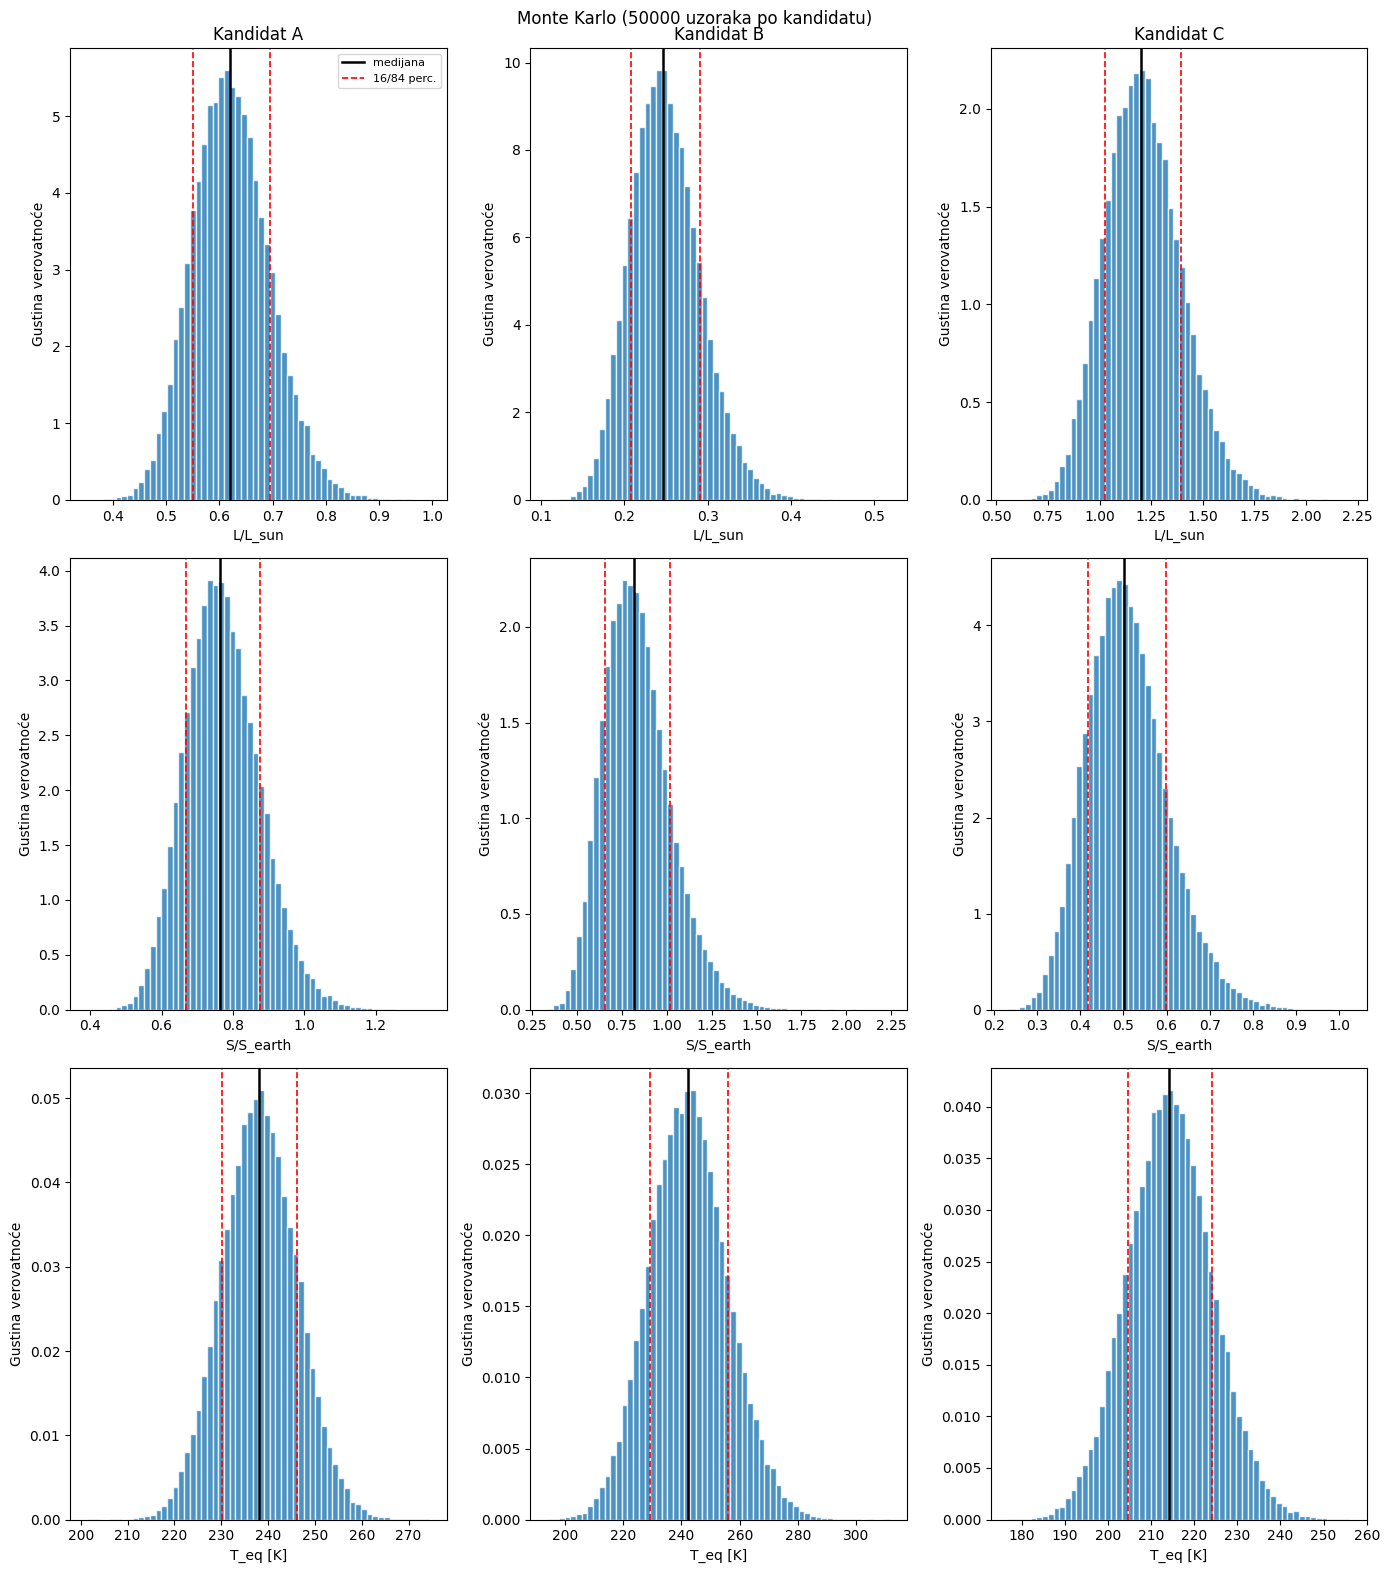

In [13]:
N = 50_000
A_ALB = 0.3
A_ERR_FRAC_C = 0.05   # pretpostavka: 5% neizvesnosti za a kandidata C (a_err = NaN)

rng3 = np.random.default_rng(SEED)

def sample_positive(mu, sigma, n, rng):
    """Normalni uzorci uslovljeni na x > 0 (ponovno izvlačenje nepozitivnih)."""
    x = rng.normal(mu, sigma, n)
    bad = x <= 0
    while bad.any():
        x[bad] = rng.normal(mu, sigma, bad.sum())
        bad = x <= 0
    return x

def sigma_a(c):
    return c['a_err'] if not np.isnan(c['a_err']) else A_ERR_FRAC_C * c['a']

# vektorizovane verzije formula (iste kao u zadatku 1, bez skalarnih provera)
def L_vec(R, T):  return R**2 * (T / T_sun)**4
def S_vec(L, a):  return L / a**2
def Teq_vec(S, A): return (S * F_earth * (1 - A) / (4 * sigma_sb))**0.25

uzorci = {}
stat = []
for _, c in candidates.iterrows():
    R_s = sample_positive(c['R'], c['R_err'], N, rng3)
    T_s = sample_positive(c['T'], c['T_err'], N, rng3)
    a_s = sample_positive(c['a'], sigma_a(c), N, rng3)

    L_s = L_vec(R_s, T_s)
    S_s = S_vec(L_s, a_s)
    Teq_s = Teq_vec(S_s, A_ALB)
    uzorci[c['name']] = {'L/L_sun': L_s, 'S/S_earth': S_s, 'T_eq [K]': Teq_s}

    for naziv, x in uzorci[c['name']].items():
        p16, med, p84 = np.percentile(x, [16, 50, 84])
        stat.append({'kandidat': c['name'], 'veličina': naziv,
                     'medijana': med, 'p16': p16, 'p84': p84,
                     '-σ (med−p16)': med - p16, '+σ (p84−med)': p84 - med})

stat = pd.DataFrame(stat)
display(stat.round(4))

velicine = list(next(iter(uzorci.values())).keys())   # 5 veličina
fig, axes = plt.subplots(len(velicine), 3, figsize=(14, 16))
for j, (ime, d) in enumerate(uzorci.items()):
    for i, v in enumerate(velicine):
        ax = axes[i, j]
        x = d[v]
        p16, med, p84 = np.percentile(x, [16, 50, 84])
        ax.hist(x, bins=60, density=True, edgecolor='white', alpha=0.8)
        ax.axvline(med, color='k', lw=1.8, label='medijana')
        ax.axvline(p16, color='r', ls='--', lw=1.2, label='16/84 perc.')
        ax.axvline(p84, color='r', ls='--', lw=1.2)
        ax.set_xlabel(v)
        ax.set_ylabel('Gustina verovatnoće')
        if i == 0:
            ax.set_title(ime)
        if i == 0 and j == 0:
            ax.legend(fontsize=8)
fig.suptitle(f'Monte Karlo ({N} uzoraka po kandidatu)')
plt.tight_layout()
plt.show()

**Zadatak 4 — Udeo unutar HZ.** U svakoj realizaciji izračunati odgovarajuće granice i proceniti $\widehat P(\mathrm{HZ})$ za konzervativnu i optimističnu definiciju. Rangirati kandidate prema oba kriterijuma i objasniti eventualne razlike.


In [7]:
# Zadatak 4 — udeo realizacija unutar HZ
def Seff_vec(T, boundary):
    if np.any((T < T_MIN) | (T > T_MAX)):
        raise ValueError('Neki uzorci T su van domena važenja polinoma.')
    S0, al, be, ga, de = hz_coeff[boundary]
    Ts = T - T_REF
    return S0 + al*Ts + be*Ts**2 + ga*Ts**3 + de*Ts**4

rng4 = np.random.default_rng(SEED)   # isti seed i redosled kao u zadatku 3

rez = []
for _, c in candidates.iterrows():
    R_s = sample_positive(c['R'], c['R_err'], N, rng4)
    T_s = sample_positive(c['T'], c['T_err'], N, rng4)
    a_s = sample_positive(c['a'], sigma_a(c), N, rng4)

    L_s = L_vec(R_s, T_s)
    d = {b: np.sqrt(L_s / Seff_vec(T_s, b)) for b in hz_coeff}

    in_cons = (d['RG'] <= a_s) & (a_s <= d['MG'])
    in_opt  = (d['RV'] <= a_s) & (a_s <= d['EM'])

    row = {'kandidat': c['name']}
    for naziv, mask in (('P_kons', in_cons), ('P_opt', in_opt)):
        p = mask.mean()
        row[naziv] = p
        row[naziv + ' ± MC'] = np.sqrt(p * (1 - p) / N)
    row['medijana d_RG'] = np.median(d['RG'])
    row['medijana d_MG'] = np.median(d['MG'])
    rez.append(row)

rez = pd.DataFrame(rez)
display(rez.round(4))

# Rangiranje (1 = najveća verovatnoća)
rez['rang kons'] = rez['P_kons'].rank(ascending=False, method='min').astype(int)
rez['rang opt']  = rez['P_opt'].rank(ascending=False, method='min').astype(int)
display(rez[['kandidat', 'P_kons', 'rang kons', 'P_opt', 'rang opt']].round(4))

,kandidat,P_kons,P_kons ± MC,P_opt,P_opt ± MC,medijana d_RG,medijana d_MG
0,Kandidat A,0.9950,0.0003,1.0000,0.0000,0.7648,1.3640
1,Kandidat B,0.8105,0.0018,0.9988,0.0002,0.4995,0.9156
2,Kandidat C,0.9687,0.0008,0.9931,0.0004,1.0346,1.8192


,kandidat,P_kons,rang kons,P_opt,rang opt
0,Kandidat A,0.9950,1,1.0000,1
1,Kandidat B,0.8105,3,0.9988,2
2,Kandidat C,0.9687,2,0.9931,3


**Zadatak 5 — Nedostajuća greška.** Izračunati udeo nedostajućih polja za neizvesnosti. Za kandidata C, čija greška velike poluose nedostaje, odvojeno pretpostaviti relativnu grešku od **1%, 5% i 10%**. Prikazati kako se menja rezultat; pretpostavke ne predstavljati kao merenja.

Nedostaje 1 od 9 polja za neizvesnost (11.1%).


,pretpostavljeno σ_a/a,σ_a [AU],S med,S p16,S p84,Teq med [K],Teq p16,Teq p84,P_kons,± MC kons,P_opt,± MC opt
0,1% (pretpostavka),0.0155,0.4995,0.4269,0.5815,214.0243,205.7819,222.3157,0.9862,0.0005,0.9983,0.0002
1,5% (pretpostavka),0.0775,0.5000,0.4158,0.6010,214.0851,204.4330,224.1620,0.9670,0.0008,0.9934,0.0004
2,10% (pretpostavka),0.1550,0.5009,0.3909,0.6481,214.1763,201.3068,228.4248,0.9099,0.0013,0.9645,0.0008


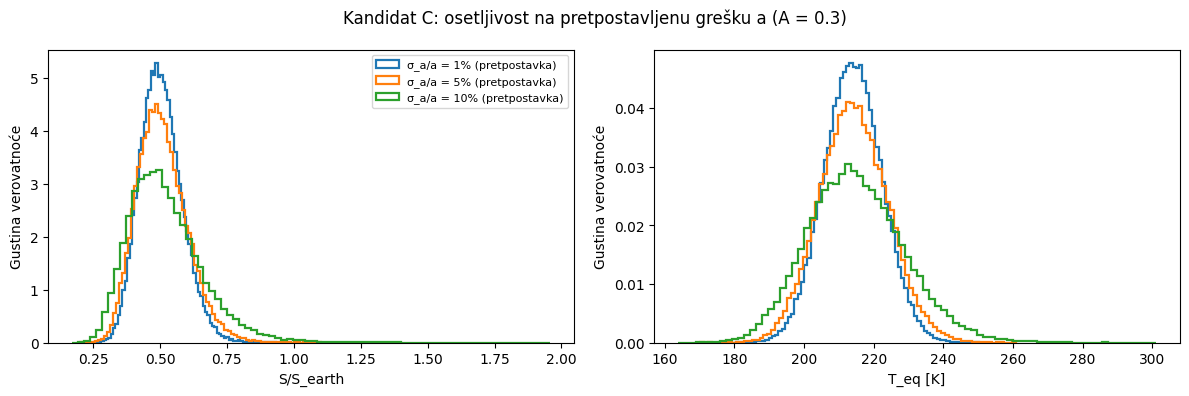

In [8]:
# Zadatak 5 — nedostajuća greška
err_cols = ['R_err', 'T_err', 'a_err']
n_polja = candidates[err_cols].size
n_nedostaje = int(candidates[err_cols].isna().sum().sum())
print(f'Nedostaje {n_nedostaje} od {n_polja} polja za neizvesnost '
      f'({100*n_nedostaje/n_polja:.1f}%).')


cC = candidates[candidates['name'] == 'Kandidat C'].iloc[0]
frakcije = (0.01, 0.05, 0.10)

rez5, uzorci5 = [], {}
for f in frakcije:
    rng5 = np.random.default_rng(SEED)          # isti seed u svakom scenariju
    R_s = sample_positive(cC['R'], cC['R_err'], N, rng5)
    T_s = sample_positive(cC['T'], cC['T_err'], N, rng5)
    a_s = sample_positive(cC['a'], f * cC['a'], N, rng5)   # pretpostavka, nije merenje

    L_s = L_vec(R_s, T_s)
    S_s = S_vec(L_s, a_s)
    Teq_s = Teq_vec(S_s, A_ALB)
    uzorci5[f] = (S_s, Teq_s)

    d = {b: np.sqrt(L_s / Seff_vec(T_s, b)) for b in hz_coeff}
    in_cons = (d['RG'] <= a_s) & (a_s <= d['MG'])
    in_opt  = (d['RV'] <= a_s) & (a_s <= d['EM'])

    s16, s50, s84 = np.percentile(S_s, [16, 50, 84])
    t16, t50, t84 = np.percentile(Teq_s, [16, 50, 84])
    p_k, p_o = in_cons.mean(), in_opt.mean()
    rez5.append({
        'pretpostavljeno σ_a/a': f'{100*f:.0f}% (pretpostavka)',
        'σ_a [AU]': f * cC['a'],
        'S med': s50, 'S p16': s16, 'S p84': s84,
        'Teq med [K]': t50, 'Teq p16': t16, 'Teq p84': t84,
        'P_kons': p_k, '± MC kons': np.sqrt(p_k*(1-p_k)/N),
        'P_opt': p_o,  '± MC opt':  np.sqrt(p_o*(1-p_o)/N),
    })

rez5 = pd.DataFrame(rez5)
display(rez5.round(4))

# Grafik: raspodela S i T_eq za tri pretpostavke
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for f, (S_s, Teq_s) in uzorci5.items():
    axes[0].hist(S_s, bins=80, density=True, histtype='step', lw=1.6,
                 label=f'σ_a/a = {100*f:.0f}% (pretpostavka)')
    axes[1].hist(Teq_s, bins=80, density=True, histtype='step', lw=1.6,
                 label=f'σ_a/a = {100*f:.0f}% (pretpostavka)')
axes[0].set_xlabel('S/S_earth');  axes[0].set_ylabel('Gustina verovatnoće')
axes[1].set_xlabel('T_eq [K]');   axes[1].set_ylabel('Gustina verovatnoće')
axes[0].legend(fontsize=8)
fig.suptitle(f'Kandidat C: osetljivost na pretpostavljenu grešku a (A = {A_ALB})')
plt.tight_layout()
plt.show()




**Zadatak 6 — Klima.** Uporediti $T_{\rm eq}$ za $A=0.1,0.3,0.6$. Za ilustraciju uvesti $T_{\rm surface}=T_{\rm eq}+\Delta T_{\rm GH}$, gde je $\Delta T_{\rm GH}=0,20,40$ K. Objasniti ograničenja te parametrizacije i zašto ovim **ne pomeramo automatski Kopparapu HZ**.

A,0.1,0.3,0.6
kandidat,,,
Kandidat A,253.5,238.1,207.0
Kandidat B,257.9,242.2,210.6
Kandidat C,228.1,214.2,186.3


,kandidat,A,ΔT_GH [K],T_surf med [K],p16,p84,P(273.15–373.15 K)
0,Kandidat A,0.1,0,253.538,245.122,262.154,0.012
1,Kandidat A,0.1,20,273.538,265.122,282.154,0.519
2,Kandidat A,0.1,40,293.538,285.122,302.154,0.993
3,Kandidat A,0.3,0,238.098,230.195,246.190,0.000
4,Kandidat A,0.3,20,258.098,250.195,266.190,0.032
5,Kandidat A,0.3,40,278.098,270.195,286.190,0.733
6,Kandidat A,0.6,0,207.013,200.141,214.047,0.000
7,Kandidat A,0.6,20,227.013,220.141,234.047,0.000
8,Kandidat A,0.6,40,247.013,240.141,254.047,0.000
9,Kandidat B,0.1,0,257.884,244.068,272.400,0.148


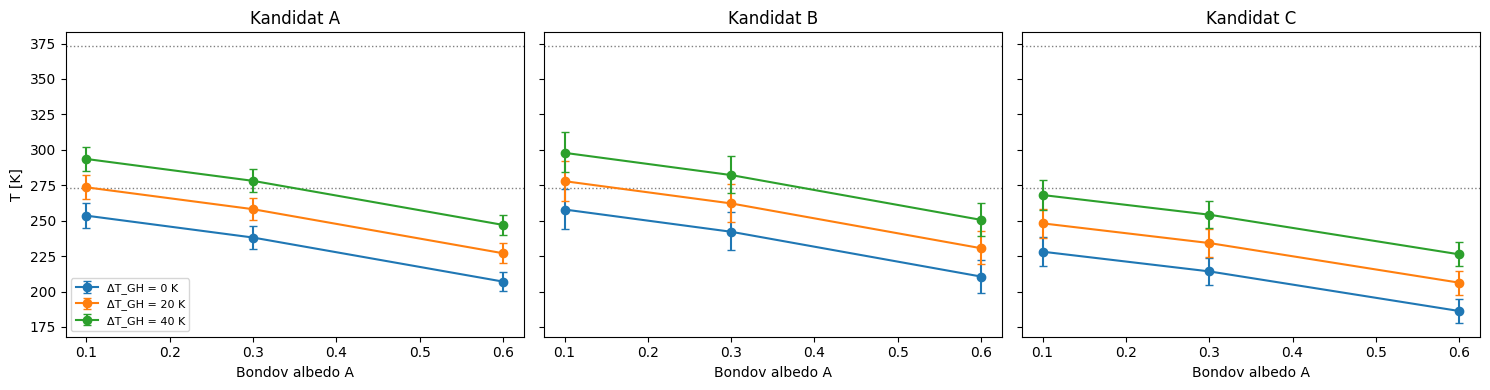

In [9]:
# Zadatak 6 — klima
albedi = (0.1, 0.3, 0.6)
dT_GH = (0, 20, 40)          # K, ilustrativna parametrizacija

rng6 = np.random.default_rng(SEED)
redovi, uzorci6 = [], {}
for _, c in candidates.iterrows():
    R_s = sample_positive(c['R'], c['R_err'], N, rng6)
    T_s = sample_positive(c['T'], c['T_err'], N, rng6)
    a_s = sample_positive(c['a'], sigma_a(c), N, rng6)
    S_s = S_vec(L_vec(R_s, T_s), a_s)

    for A in albedi:
        Teq_s = Teq_vec(S_s, A)
        uzorci6[(c['name'], A)] = Teq_s
        for dT in dT_GH:
            Ts = Teq_s + dT
            p16, med, p84 = np.percentile(Ts, [16, 50, 84])
            redovi.append({
                'kandidat': c['name'], 'A': A, 'ΔT_GH [K]': dT,
                'T_surf med [K]': med, 'p16': p16, 'p84': p84,
                'P(273.15–373.15 K)': np.mean((Ts >= 273.15) & (Ts <= 373.15)),
            })

rez6 = pd.DataFrame(redovi)

# 1) Poređenje T_eq po albedu (ΔT = 0)
display(rez6[rez6['ΔT_GH [K]'] == 0]
        .pivot(index='kandidat', columns='A', values='T_surf med [K]').round(1))

# 2) Pun rezultat: T_surface
display(rez6.round(3))

# 3) Grafik: medijana T_surface (sa 16–84) u zavisnosti od A, po ΔT_GH
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (_, c) in zip(axes, candidates.iterrows()):
    for dT in dT_GH:
        sub = rez6[(rez6['kandidat'] == c['name']) & (rez6['ΔT_GH [K]'] == dT)]
        ax.errorbar(sub['A'], sub['T_surf med [K]'],
                    yerr=[sub['T_surf med [K]'] - sub['p16'], sub['p84'] - sub['T_surf med [K]']],
                    marker='o', capsize=3, label=f'ΔT_GH = {dT} K')
    ax.axhline(273.15, color='gray', ls=':', lw=1)
    ax.axhline(373.15, color='gray', ls=':', lw=1)
    ax.set_title(c['name']); ax.set_xlabel('Bondov albedo A')
axes[0].set_ylabel('T [K]'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()



**Zadatak 7 — Naučni memo (150–200 reči).** Sažeti metod, rezultate rangiranja, ulogu nedostajućih grešaka, uticaj klimatskih pretpostavki i ograničenja. Objasniti zašto $\widehat P(\mathrm{HZ})$ **nije** verovatnoća života.

**Metod:** za tri sintetička kandidata iz $R_\star$, $T_{\rm eff}$ i $a$ izračunati su $L$, $S$ i $T_{\rm eq}$, a granice nastanjive zone dobijene su Kopparapu et al. (2014) polinomima. Neizvesnosti su propagirane Monte Karlom ($N=50\,000$, `seed=42`) uz normalne raspodele odsečene na pozitivne vrednosti.

**Rangiranje:** po konzervativnoj zoni A (0,995) > C (0,969) > B (0,811); po optimističnoj A (1,000) > B (0,999) > C (0,993). Redosled B i C se menja jer je B blizu unutrašnje, a C blizu spoljašnje granice, koje optimistična definicija pomera.

**Nedostajuće greške:** kandidatu C nedostaje 1 od 9 polja (11,1%); pretpostavke od 1, 5 i 10% daju $\widehat P_{\rm kons}$ = 0,986, 0,967 i 0,910, pa rezultat zavisi od pretpostavke, a ne od merenja.

**Klima:** albedo i $\Delta T_{\rm GH}$ menjaju $T_{\rm eq}$ i ilustrativnu $T_{\rm surface}$, ali ne pomeraju automatski Kopparapu granice.

**Ograničenja:** sintetički podaci, simetrične greške, bez korelacija, kružne orbite, gruba parametrizacija.

**Zašto $\widehat P(\mathrm{HZ})$ nije verovatnoća života:** to je samo udeo realizacija unutar zone pri datom modelu; ne sadrži atmosferu, sastav planete, evoluciju ni biologiju, pa nije verovatnoća života.